# Agile flex: walkthrough

Scheduling an EV and a home battery against 12 months of Octopus Agile half-hourly prices (London, region C).
This notebook is the interview version: each section answers one question and runs in about two minutes.

1. What does the data look like?
2. How does the optimiser decide, on one day?
3. What does it save over a year, against two simpler strategies?
4. Where does the saving come from: the car or the battery?
5. What does it cost to also cut carbon?
6. How much is lost when it plans on a price forecast instead of real prices?

The same optimiser also runs the daily planner (`python -m agileflex plan`) and sits behind the Off-peak web app; see the README.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from agileflex.common import load_config, load_data, windows
from agileflex.strategies import baseline, rule_based, optimised, run
from agileflex import report
cfg = load_config(); df = load_data(cfg); wins = windows(df, cfg)
print(f"{len(df):,} half-hours, {len(wins)} daily planning windows (16:00 to 16:00)")

17,520 half-hours, 364 daily planning windows (16:00 to 16:00)


## 1. The data
Agile prices are set day-ahead, half-hour by half-hour. The shape that matters: a reliable 16:00-19:00 peak, cheap nights, and in windy or sunny spells, prices below zero.

In [2]:
local = df.assign(slot=df['local'].dt.hour + df['local'].dt.minute/60, month=df['local'].dt.month)
prof = local.groupby('slot')['price'].quantile([0.1, 0.5, 0.9]).unstack()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].fill_between(prof.index, prof[0.1], prof[0.9], color='#2a78d6', alpha=0.2, lw=0, label='10th-90th percentile')
ax[0].plot(prof.index, prof[0.5], color='#2a78d6', lw=2, label='median')
ax[0].axvspan(16, 19, color='#f1efe9', zorder=0); ax[0].set_xlabel('local time'); ax[0].set_ylabel('p/kWh')
ax[0].set_title('Agile price by time of day', loc='left'); ax[0].legend(frameon=False)
ax[1].plot(df.index, df['gco2'].rolling(48*7).mean(), color='#1baf7a', lw=2)
ax[1].set_title('London carbon intensity, 7-day mean (gCO2/kWh)', loc='left')
plt.tight_layout()
print(f"Mean price {df.price.mean():.1f}p, negative in {(df.price<0).sum()} half-hours, max {df.price.max():.1f}p")

Mean price 20.9p, negative in 499 half-hours, max 86.7p


## 2. One day, step by step
At 16:00 the plan for the next 24 hours is made. The car arrives at 18:00 and needs 30 kWh by 07:30; the battery starts full and must be full again by 16:00 tomorrow. The optimiser is a small mixed-integer program (see `optimise.py` for the full formulation): ~50 half-hours x 5 variables, solved in a few hundredths of a second.

{'Baseline': '£8.16', 'Rule-based': '£5.70', 'Optimised': '£5.66'}


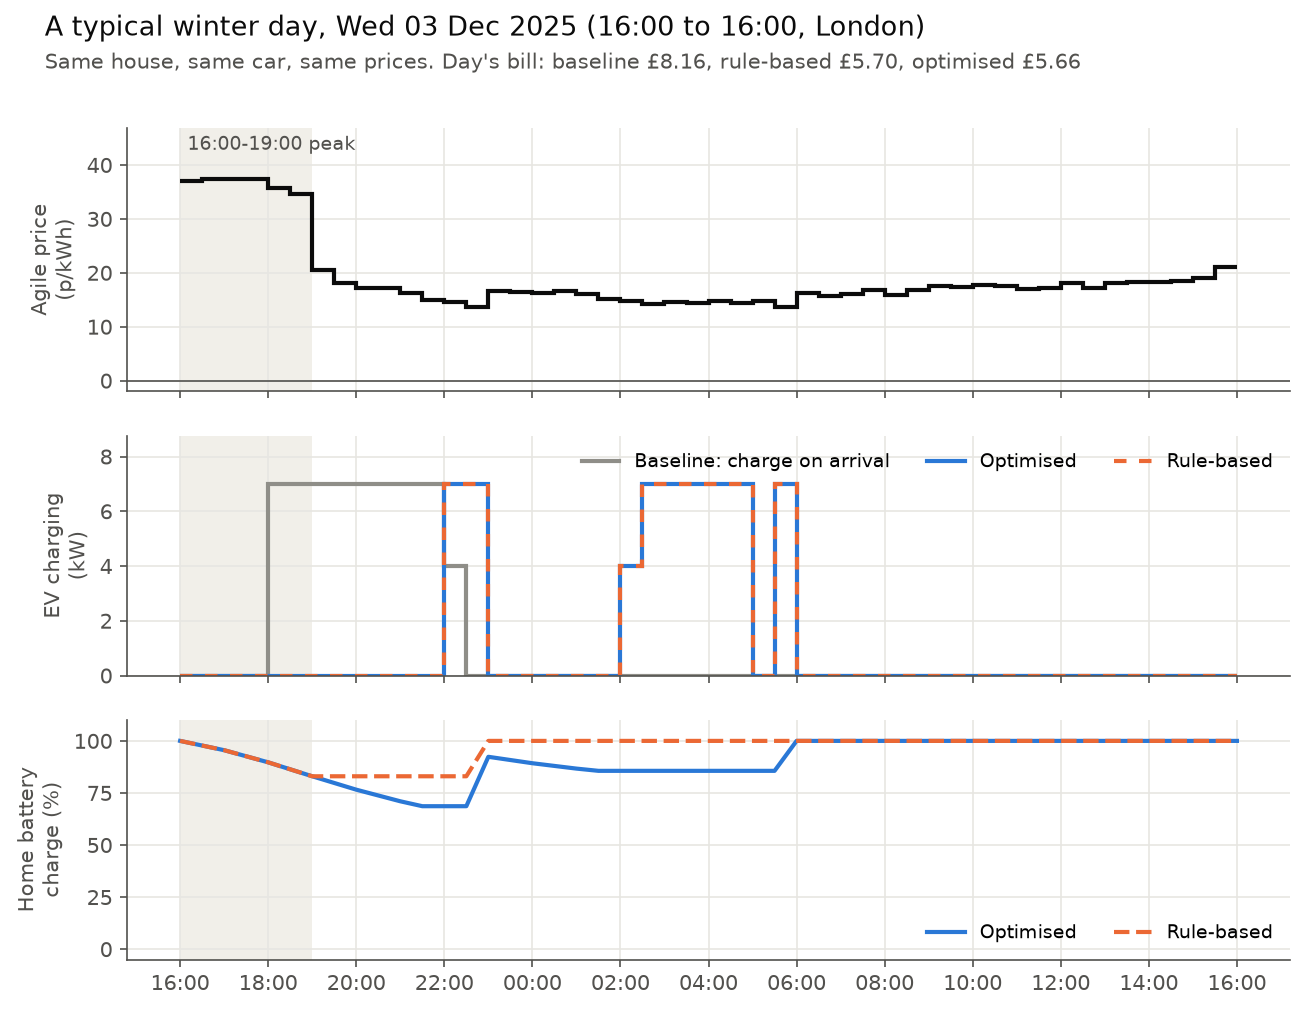

In [3]:
w = report.typical_winter_window(wins, cfg)
day = {name: f(w, cfg) for name, f in [('Baseline', baseline), ('Rule-based', rule_based), ('Optimised', optimised)]}
print({k: f"£{v['cost_p'].sum()/100:.2f}" for k, v in day.items()})
report.chart_day(w, cfg, '../outputs/headline_winter_day.png')
from IPython.display import Image; Image('../outputs/headline_winter_day.png', width=800)

## 3. Twelve months, three strategies
Same house, same car, same prices. The house load is a synthetic 2,700 kWh/year profile; the standing charge is identical across strategies and left out.

In [4]:
sched = report.run_all(cfg, df, wins, verbose=False)
table = pd.DataFrame({k: report.metrics(v, sched['Baseline']) for k, v in sched.items()})
table

,Baseline,Rule-based,Optimised,"Optimised, EV only",Optimised + carbon
Annual cost (GBP),3591.43,2294.82,2142.13,2409.24,2144.94
Saving vs baseline (GBP),0.00,1296.61,1449.30,1182.19,1446.49
Saving vs baseline (%),0.00,36.10,40.40,32.90,40.30
Cost per kWh used (p),26.39,16.86,15.74,17.70,15.76
Emissions (kgCO2),2233.40,1827.30,1744.20,1851.40,1700.50
CO2 saved vs baseline (kg),0.00,406.10,489.20,382.00,532.90
Peak 16-19 import (kWh),3059.20,0.00,4.30,511.20,5.00
kWh moved out of 16-19 peak,0.00,3059.20,3054.80,2548.00,3054.10
Negative-price half-hours used,1.00,106.00,269.00,75.00,269.00
kWh bought at negative prices,3.50,303.70,657.50,252.00,656.80


## 4. Where the saving comes from
Running the same optimiser with the battery removed separates the two assets.

In [5]:
b, ev, full = (table.loc['Annual cost (GBP)', k] for k in ['Baseline', 'Optimised, EV only', 'Optimised'])
print(f"Smart EV charging alone: £{b-ev:,.0f}/yr  ({100*(b-ev)/b:.0f}% of the bill)")
print(f"Adding the 10 kWh battery: £{ev-full:,.0f}/yr more")
print(f"Battery cycles per year: {table.loc['Battery throughput (kWh)','Optimised']/cfg['battery']['capacity_kwh']:.0f}")

Smart EV charging alone: £1,182/yr  (33% of the bill)
Adding the 10 kWh battery: £267/yr more
Battery cycles per year: 284


## 5. The cost of cutting carbon
Add a carbon price to the objective and trace the trade-off. The first cuts are almost free, because cheap Agile hours and low-carbon hours are mostly the same hours (wind). Over the full year a 15p/kg weight costs about £3 to save 44 kg, roughly £64 per tonne.

In [6]:
rows = []
for wt in [0, 5, 15, 30, 60, 120]:
    s = run(optimised, wins[::3], cfg, carbon_weight=wt)
    rows.append({'carbon weight (p/kgCO2)': wt, 'cost (GBP)': s['cost_p'].sum()/100, 'kgCO2': s['kgco2'].sum()})
curve = pd.DataFrame(rows).set_index('carbon weight (p/kgCO2)')
curve['extra cost vs w=0 (GBP)'] = curve['cost (GBP)'] - curve['cost (GBP)'].iloc[0]
curve['kgCO2 saved vs w=0'] = curve['kgCO2'].iloc[0] - curve['kgCO2']
curve.round(1)  # every 3rd day, to keep the notebook quick

,cost (GBP),kgCO2,extra cost vs w=0 (GBP),kgCO2 saved vs w=0
carbon weight (p/kgCO2),,,,
0,738.3,583.0,0.0,0.0
5,738.5,575.9,0.2,7.1
15,739.3,568.0,0.9,14.9
30,741.4,558.7,3.0,24.3
60,745.7,548.2,7.4,34.8
120,754.3,538.4,16.0,44.6


## 6. Planning on a forecast
If the plan had to be committed before Octopus publishes tomorrow's prices, it would act on a forecast. A ridge regression (yesterday's and last week's price for that half-hour, the Carbon Intensity API's own forecast, time of day, weekend) is refit every day on the previous 8 weeks, then the plan is scored on the real prices.

In [7]:
fc = report.forecast_study(cfg, df, wins)
pd.Series({
  'Days tested': fc['days'],
  'Forecast error, ridge (MAE p/kWh)': fc['mae_ridge_p'],
  'Forecast error, yesterday-repeats (MAE p/kWh)': fc['mae_naive_p'],
  'Lost vs perfect foresight, ridge (GBP)': fc['regret_ridge_gbp'],
  'Lost vs perfect foresight, naive (GBP)': fc['regret_naive_gbp'],
  'Share of the saving kept, ridge (%)': fc['share_of_saving_kept_ridge_pct'],
  'Share of the saving kept, naive (%)': fc['share_of_saving_kept_naive_pct'],
})

  forecasting prices (walk-forward ridge) ...


Days tested                                      307.00
Forecast error, ridge (MAE p/kWh)                  4.14
Forecast error, yesterday-repeats (MAE p/kWh)      4.86
Lost vs perfect foresight, ridge (GBP)            98.98
Lost vs perfect foresight, naive (GBP)           156.89
Share of the saving kept, ridge (%)               92.20
Share of the saving kept, naive (%)               87.70
dtype: float64

## Takeaways
* Most of the value is simply **not charging the car at 18:00**. A one-line rule captures ~90% of what the optimiser finds.
* The optimiser's extra comes from **using the battery all day, not just at the peak**: ~280 cycles a year against intraday spreads, and 2.5x more negative-price half-hours used. Degradation is not modelled, so this is an upper bound on battery value.
* Cheap and clean line up: price-optimal charging already cuts 22% of emissions, and a modest carbon price takes a little more for a few pounds.
* Forecast error costs money, but a simple model still keeps most of the saving. Better forecasts are worth roughly the gap between the ridge and perfect-foresight rows.